In [1]:
from pathlib import Path
import sys
import yaml
import numpy as np
import matplotlib.pyplot as plt


def find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for path in [cwd, *cwd.parents]:
        if (path / "model_training" / "trainer.py").exists():
            return path
    raise FileNotFoundError("Could not find repo root containing model_training/trainer.py")


REPO_ROOT = find_repo_root()
MODEL_TRAINING_DIR = REPO_ROOT / "model_training"

if str(MODEL_TRAINING_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_TRAINING_DIR))

from helpers.dataset import BrainToTextDataset, train_test_split_indicies


# Update these if you want a different run or sample.
CONFIG_PATH = REPO_ROOT / "model_training" / "logs" / "snn" / "2026-04-04_15-31-23_327141_snn_pid47176" / "configs" / "trainer_config_resolved.yaml"
SPLIT = "train"  # "train" or "val"
BATCH_INDEX = 0
TRIAL_IN_BATCH = 0
SAVE_PATH = None  # Example: REPO_ROOT / "model_training" / "evaluate_model" / "trainer_input_channels.png"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

dataset_dir = (MODEL_TRAINING_DIR / config["dataset"]["dataset_dir"]).resolve()
sessions = config["dataset"]["sessions"]
feature_subset = config["dataset"].get("feature_subset")

train_file_paths = [dataset_dir / session / "data_train.hdf5" for session in sessions]
val_file_paths = [dataset_dir / session / "data_val.hdf5" for session in sessions]


In [2]:
train_trials, _ = train_test_split_indicies(
    file_paths=train_file_paths,
    test_percentage=0,
    seed=config["dataset"]["seed"],
    bad_trials_dict=None,
)

_, val_trials = train_test_split_indicies(
    file_paths=val_file_paths,
    test_percentage=1,
    seed=config["dataset"]["seed"],
    bad_trials_dict=None,
)

if SPLIT == "train":
    dataset = BrainToTextDataset(
        trial_indicies=train_trials,
        split="train",
        days_per_batch=config["dataset"]["days_per_batch"],
        n_batches=1,
        batch_size=config["dataset"]["batch_size"],
        must_include_days=None,
        random_seed=config["dataset"]["seed"],
        feature_subset=feature_subset,
    )
elif SPLIT == "val":
    dataset = BrainToTextDataset(
        trial_indicies=val_trials,
        split="test",
        days_per_batch=None,
        n_batches=None,
        batch_size=config["dataset"]["batch_size"],
        must_include_days=None,
        random_seed=config["dataset"]["seed"],
        feature_subset=feature_subset,
    )
else:
    raise ValueError("SPLIT must be 'train' or 'val'")

batch = dataset[BATCH_INDEX]
sample = batch["input_features"][TRIAL_IN_BATCH]
n_time_steps = int(batch["n_time_steps"][TRIAL_IN_BATCH])
sample = sample[:n_time_steps].cpu().numpy()

print(f"Loaded sample shape: {sample.shape} (time, channels)")


Loaded sample shape: (547, 512) (time, channels)


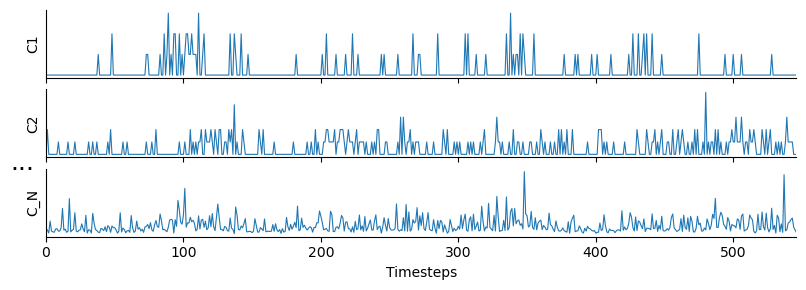

In [ ]:
def plot_first_two_and_last_channel(sample_array: np.ndarray, save_path: Path | None = None):
    if sample_array.ndim != 2:
        raise ValueError(f"Expected a 2D array shaped (time, channels), got {sample_array.shape}")

    n_time_steps, n_channels = sample_array.shape
    channel_indices = [0, 1, n_channels - 1]
    channel_labels = ["C1", "C2", f"Cn"]
    time_axis = np.arange(n_time_steps)

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(8.0, 3.0),
        sharex=True,
    )

    for ax, channel_idx, channel_label in zip(axes, channel_indices, channel_labels):
        ax.plot(time_axis, sample_array[:, channel_idx], color="#1f77b4", linewidth=0.8)
        ax.set_ylabel(channel_label)
        ax.set_yticks([])
        ax.margins(x=0)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[-1].set_xlabel("Timesteps")

    fig.tight_layout(h_pad=0.45)
    fig.canvas.draw()

    last_box = axes[2].get_position()
    extra_gap = 0.08
    axes[2].set_position([last_box.x0, last_box.y0 - extra_gap, last_box.width, last_box.height])

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, axes


fig, axes = plot_first_two_and_last_channel(sample, SAVE_PATH)
plt.show()
